In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import time
import glob

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

csv_files = glob.glob(
    "/content/drive/MyDrive/Data Mining/Datasets/PaySim/PS_20174392719_1491204439457_log.csv"
)

print("Files found:")
for file in csv_files:
    print(file)

DATA_PATH = csv_files[0]

df = pd.read_csv(DATA_PATH)

print("\nOriginal shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicates:", df.duplicated().sum())

print("\nFraud distribution:")
print(df["isFraud"].value_counts())

print("\nFraud percentage:")
print(
    df["isFraud"]
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

df = df.drop_duplicates().reset_index(drop=True)

df = df.sort_values("step").reset_index(drop=True)

df["orig_balance_error"] = (
    df["oldbalanceOrg"]
    - df["amount"]
    - df["newbalanceOrig"]
)

df["dest_balance_error"] = (
    df["oldbalanceDest"]
    + df["amount"]
    - df["newbalanceDest"]
)

df["orig_zero_balance"] = (
    df["oldbalanceOrg"] == 0
).astype("int8")

df["dest_zero_balance"] = (
    df["newbalanceDest"] == 0
).astype("int8")

df["amount_log"] = np.log1p(
    df["amount"].clip(lower=0)
)

df["oldbalanceOrg_log"] = np.log1p(
    df["oldbalanceOrg"].clip(lower=0)
)

df["newbalanceOrig_log"] = np.log1p(
    df["newbalanceOrig"].clip(lower=0)
)

df["oldbalanceDest_log"] = np.log1p(
    df["oldbalanceDest"].clip(lower=0)
)

df["newbalanceDest_log"] = np.log1p(
    df["newbalanceDest"].clip(lower=0)
)

df["amount_to_orig_balance"] = np.where(
    df["oldbalanceOrg"] > 0,
    df["amount"] / df["oldbalanceOrg"],
    0
)

df["amount_to_dest_balance"] = np.where(
    df["oldbalanceDest"] > 0,
    df["amount"] / df["oldbalanceDest"],
    0
)

df["sender_transaction_count"] = (
    df.groupby("nameOrig").cumcount()
)

df["receiver_transaction_count"] = (
    df.groupby("nameDest").cumcount()
)

df["same_account"] = (
    df["nameOrig"] == df["nameDest"]
).astype("int8")

df["is_transfer_or_cashout"] = (
    df["type"].isin(["TRANSFER", "CASH_OUT"])
).astype("int8")

df = df.drop(
    columns=[
        "nameOrig",
        "nameDest",
        "isFlaggedFraud"
    ],
    errors="ignore"
)

split_index = int(len(df) * 0.70)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("\nTraining shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nTraining step range:")
print(
    train_df["step"].min(),
    "to",
    train_df["step"].max()
)

print("\nTest step range:")
print(
    test_df["step"].min(),
    "to",
    test_df["step"].max()
)

print("\nTraining fraud distribution:")
print(train_df["isFraud"].value_counts())

print(
    train_df["isFraud"]
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

print("\nTest fraud distribution:")
print(test_df["isFraud"].value_counts())

print(
    test_df["isFraud"]
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

X_train = train_df.drop(columns=["isFraud"])
y_train = train_df["isFraud"]

X_test = test_df.drop(columns=["isFraud"])
y_test = test_df["isFraud"]

categorical_features = [
    "type"
]

numerical_features = [
    col
    for col in X_train.columns
    if col not in categorical_features
]

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=12,
        min_samples_leaf=10
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=4,
        max_depth=20,
        min_samples_leaf=5
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=4
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for model_name, model in models.items():

    pipeline = ImbPipeline([
        (
            "preprocessor",
            preprocessor
        ),
        (
            "smote",
            SMOTE(
                sampling_strategy=0.1,
                random_state=42,
                k_neighbors=5
            )
        ),
        (
            "model",
            model
        )
    ])

    start_time = time.time()

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc",
            "pr_auc": "average_precision"
        },
        n_jobs=1,
        return_train_score=False
    )

    elapsed = time.time() - start_time

    results.append({
        "Model": model_name,
        "Strategy": "SMOTE",
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
        "Time_seconds": elapsed
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["PR-AUC", "F1"],
    ascending=False
).reset_index(drop=True)

print("\nPAYSIM SMOTE-ONLY CV RESULTS")

print(
    results_df.to_string(index=False)
)

winner = results_df.iloc[0]

print("\nWINNER")

print("Model:", winner["Model"])
print("Strategy:", winner["Strategy"])
print("Accuracy:", winner["Accuracy"])
print("Precision:", winner["Precision"])
print("Recall:", winner["Recall"])
print("F1:", winner["F1"])
print("ROC-AUC:", winner["ROC-AUC"])
print("PR-AUC:", winner["PR-AUC"])

Files found:
/content/drive/MyDrive/Data Mining/Datasets/PaySim/PS_20174392719_1491204439457_log.csv

Original shape: (6362620, 11)

Columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Missing values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicates: 0

Fraud distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud percentage:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64

Training shape: (4453834, 23)
Test shape: (1908786, 23)

Training step range:
1 to 323

Test step range:
323 to 743

Training fraud distribution:
isFraud
0    4450191
1       3643
Name: count, dtype: int64
isFraud
0    99.9182
1     0.0818
Name: proportion, dtype: float64



In [ ]:
import time
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


print("=" * 70)
print("FINAL PAYSIM TEST EVALUATION")
print("=" * 70)

final_model = ImbPipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "smote",
        SMOTE(
            sampling_strategy=0.1,
            random_state=42
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=100,
            max_depth=20,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=42
        )
    )
])


print("\nTraining Random Forest + SMOTE on complete training set...")

training_start = time.time()

final_model.fit(
    X_train,
    y_train
)

training_time = time.time() - training_start

print(
    f"Training Time: {training_time:.2f} seconds"
)


print("\nEvaluating on untouched test set...")

testing_start = time.time()

y_pred = final_model.predict(
    X_test
)

y_prob = final_model.predict_proba(
    X_test
)[:, 1]

testing_time = time.time() - testing_start


accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

pr_auc = average_precision_score(
    y_test,
    y_prob
)

cm = confusion_matrix(
    y_test,
    y_pred
)


print("\n" + "=" * 70)
print("FINAL PAYSIM TEST RESULTS")
print("=" * 70)

print(f"Model          : Random Forest")
print(f"Strategy       : SMOTE")
print(f"Accuracy       : {accuracy:.6f}")
print(f"Precision      : {precision:.6f}")
print(f"Recall         : {recall:.6f}")
print(f"F1-Score       : {f1:.6f}")
print(f"ROC-AUC        : {roc_auc:.6f}")
print(f"PR-AUC         : {pr_auc:.6f}")
print(f"Training Time  : {training_time:.2f} seconds")
print(f"Testing Time   : {testing_time:.4f} seconds")


print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Not Fraud",
            "Fraud"
        ],
        digits=4
    )
)


print("\nConfusion Matrix:")
print(cm)


print("\n" + "=" * 70)
print("PAYSim TEST SUMMARY")
print("=" * 70)

print(
    pd.DataFrame({
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "ROC-AUC",
            "PR-AUC",
            "Training Time",
            "Testing Time"
        ],
        "Value": [
            accuracy,
            precision,
            recall,
            f1,
            roc_auc,
            pr_auc,
            training_time,
            testing_time
        ]
    }).to_string(index=False)
)

FINAL PAYSIM TEST EVALUATION

Training Random Forest + SMOTE on complete training set...
Training Time: 1812.92 seconds

Evaluating on untouched test set...

FINAL PAYSIM TEST RESULTS
Model          : Random Forest
Strategy       : SMOTE
Accuracy       : 0.999999
Precision      : 0.999781
Recall         : 0.999781
F1-Score       : 0.999781
ROC-AUC        : 1.000000
PR-AUC         : 0.999999
Training Time  : 1812.92 seconds
Testing Time   : 19.6255 seconds

Classification Report:
              precision    recall  f1-score   support

   Not Fraud     1.0000    1.0000    1.0000   1904216
       Fraud     0.9998    0.9998    0.9998      4570

    accuracy                         1.0000   1908786
   macro avg     0.9999    0.9999    0.9999   1908786
weighted avg     1.0000    1.0000    1.0000   1908786


Confusion Matrix:
[[1904215       1]
 [      1    4569]]

PAYSim TEST SUMMARY
       Metric       Value
     Accuracy    0.999999
    Precision    0.999781
       Recall    0.999781
     F

FINAL TEST COMPARISON
       Dataset        Risk Type Selected Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
        PaySim            Fraud  Random Forest   99.9999    99.9781 99.9781   99.9781 100.0000 99.9999
        SAML-D Money Laundering        XGBoost   99.9568    74.1255 92.6986   82.3782  99.9475 93.5894
Botswana Churn   Customer Churn        XGBoost   99.4379    96.9718 98.4626   97.7115  99.9803 99.8634


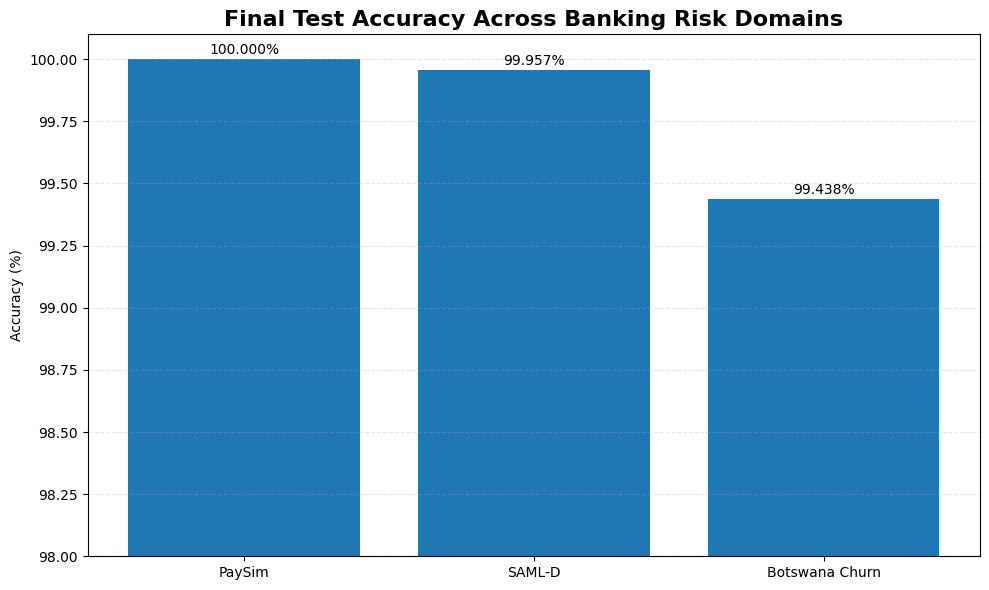

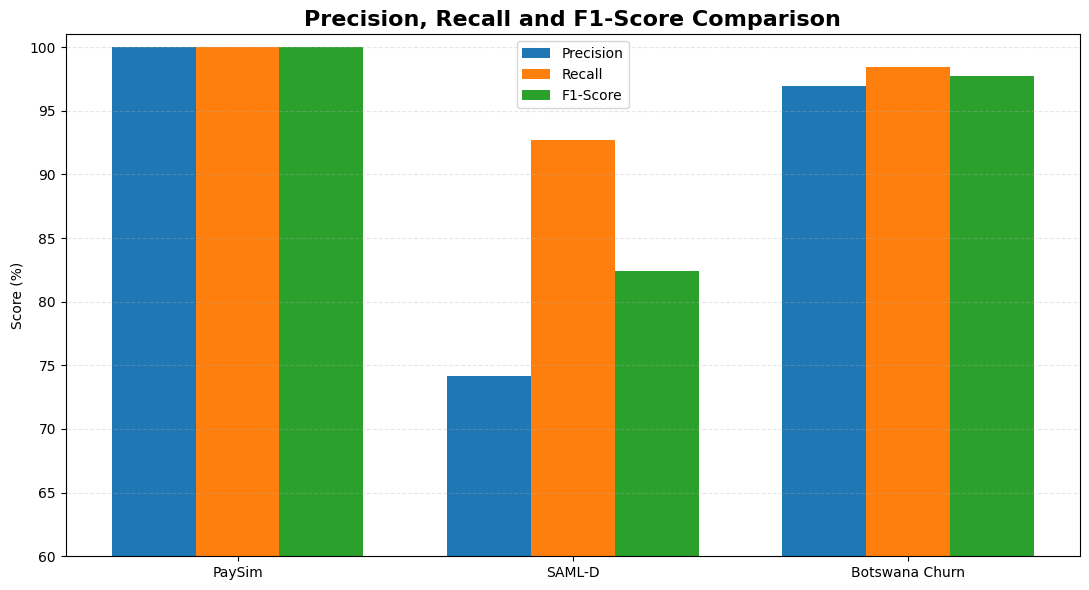

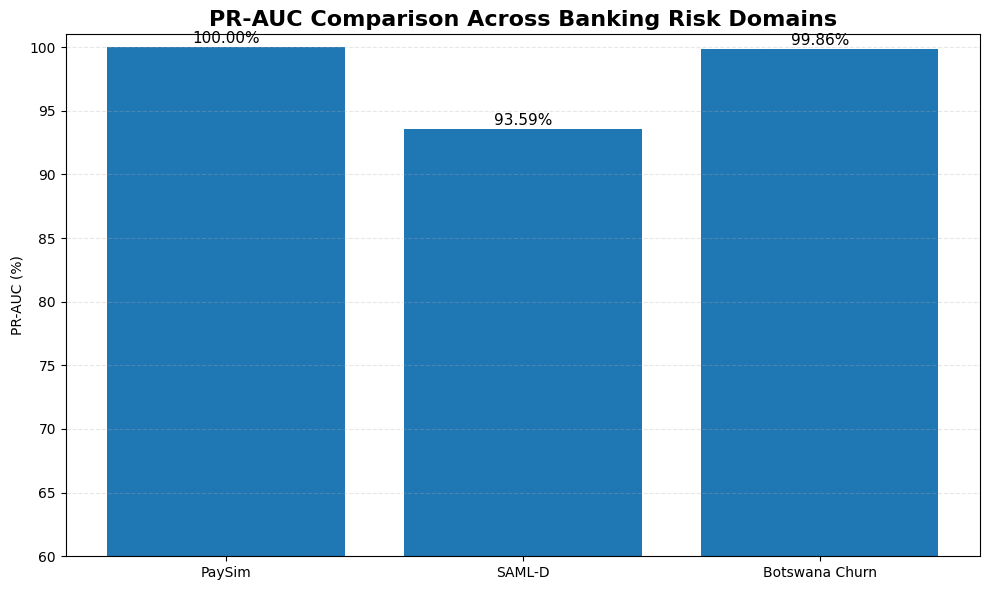

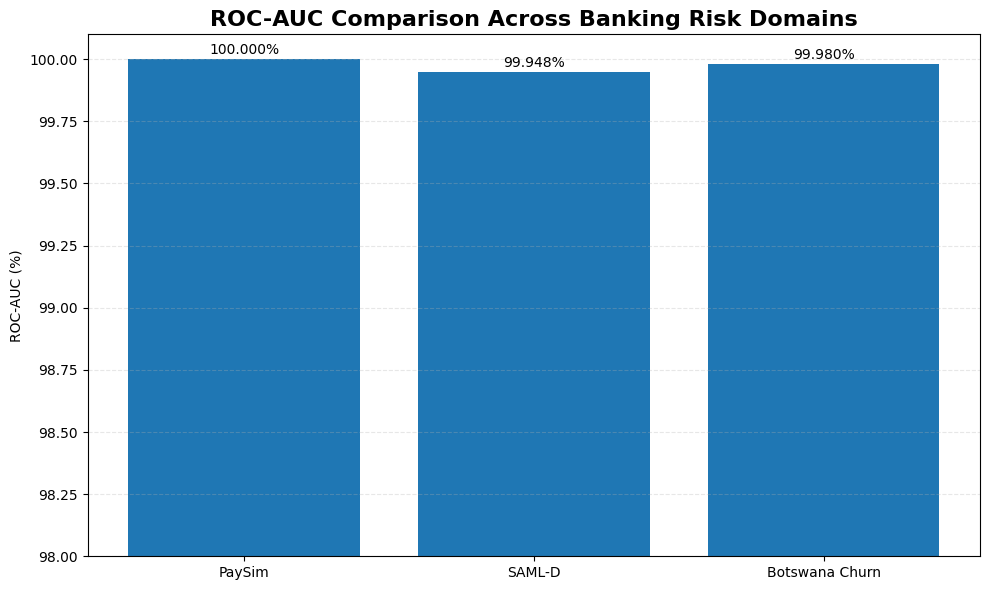

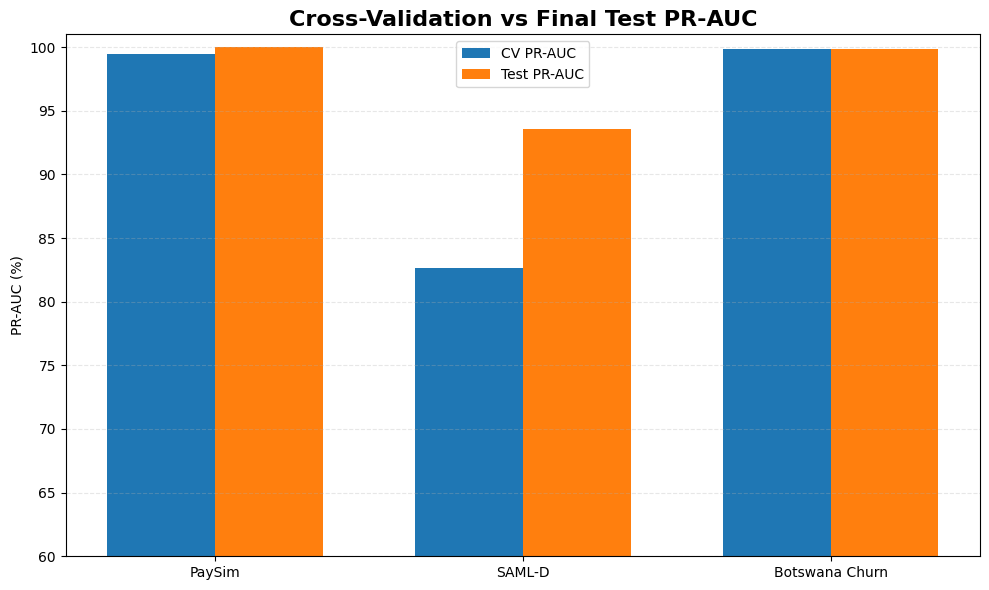

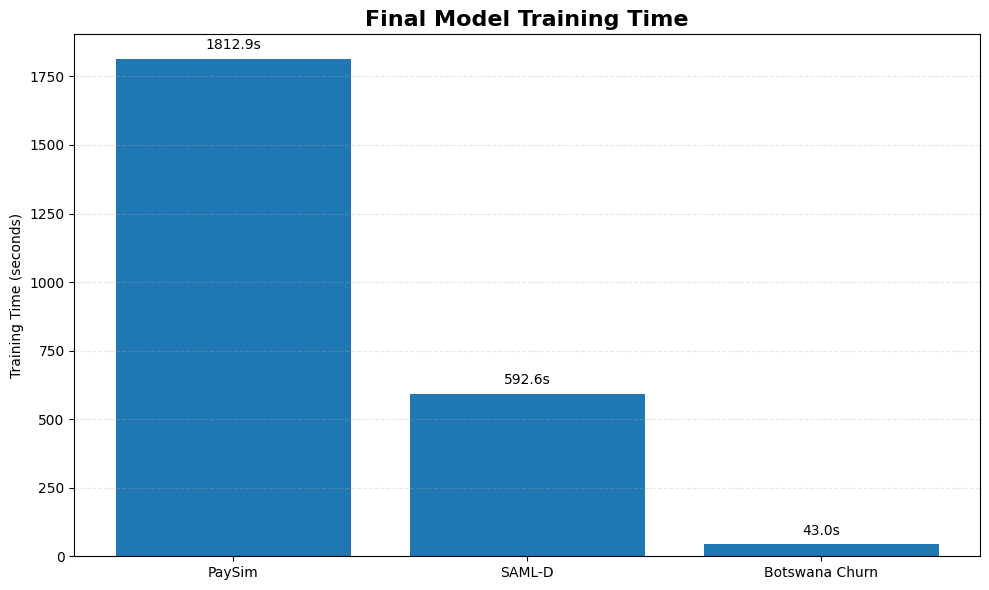

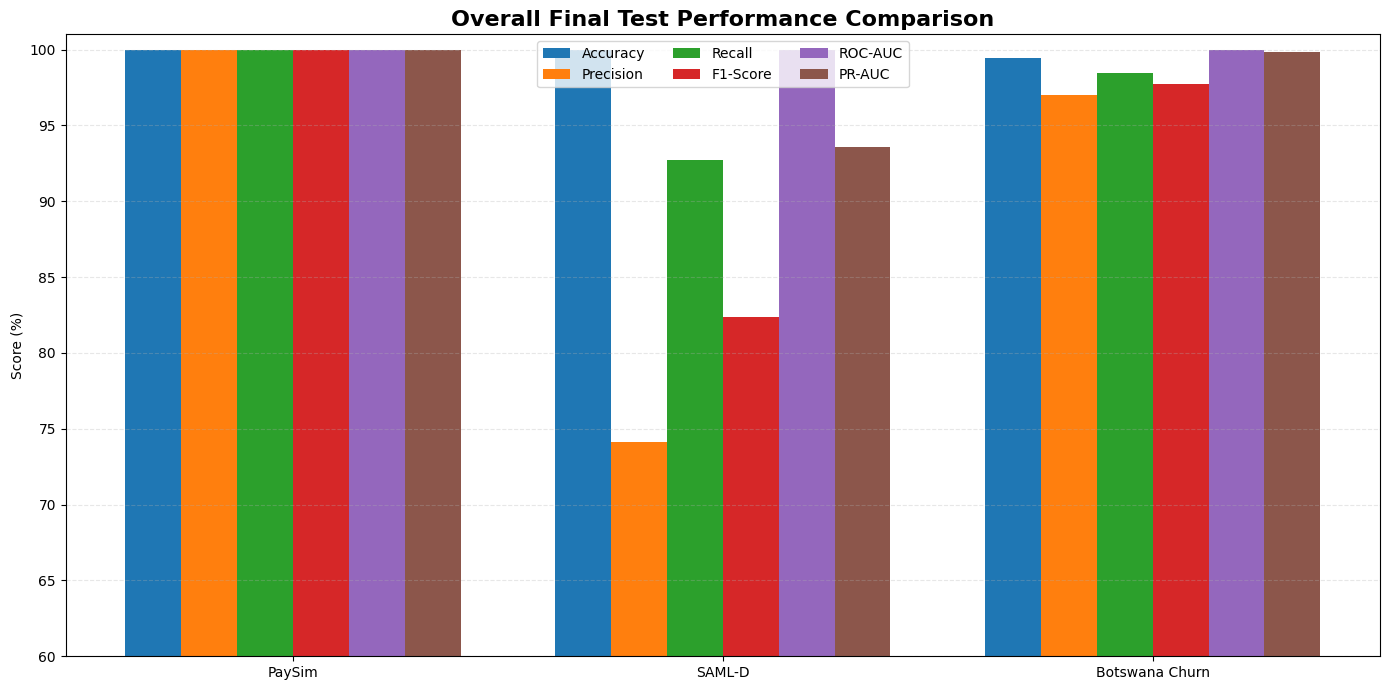

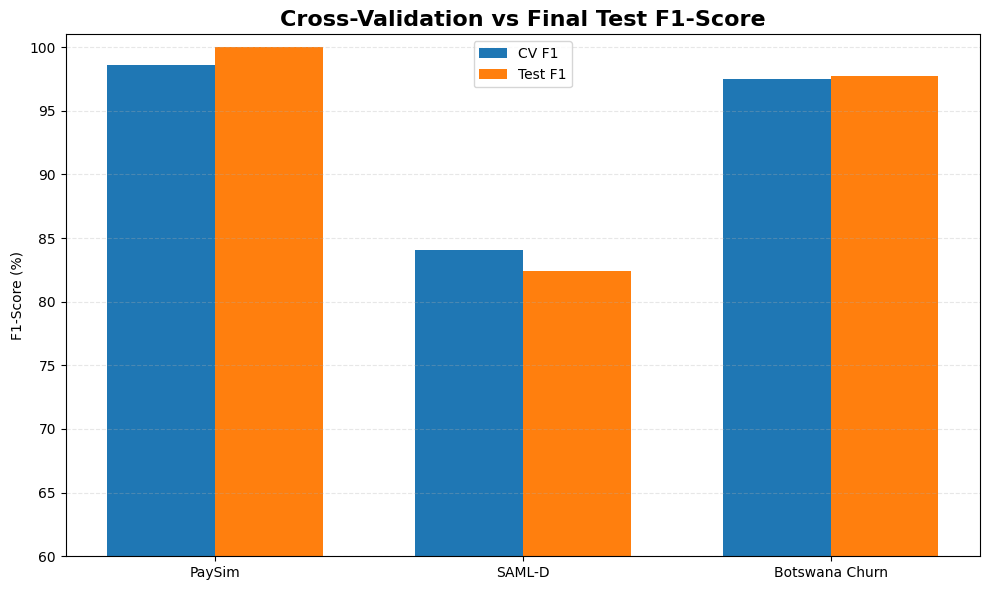


ALL REPORT FILES GENERATED
01_accuracy_comparison.png
02_precision_recall_f1_comparison.png
03_pr_auc_comparison.png
04_roc_auc_comparison.png
05_cv_vs_test_pr_auc.png
06_training_time_comparison.png
07_overall_performance_comparison.png
08_cv_vs_test_f1.png
cv_comparison.csv
dataset_methodology_summary.csv
dataset_size_summary.csv
final_test_comparison.csv
final_test_percentage_table.csv
model_selection_summary.csv

Output folder:
/content/final_report_outputs


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

output_dir = "final_report_outputs"
os.makedirs(output_dir, exist_ok=True)



test_results = pd.DataFrame({

    "Dataset": [
        "PaySim",
        "SAML-D",
        "Botswana Churn"
    ],

    "Risk Type": [
        "Fraud",
        "Money Laundering",
        "Customer Churn"
    ],

    "Selected Model": [
        "Random Forest",
        "XGBoost",
        "XGBoost"
    ],

    "Strategy": [
        "SMOTE",
        "SMOTE",
        "SMOTE"
    ],

    "Accuracy": [
        0.999999,
        0.999568,
        0.994379
    ],

    "Precision": [
        0.999781,
        0.741255,
        0.969718
    ],

    "Recall": [
        0.999781,
        0.926986,
        0.984626
    ],

    "F1-Score": [
        0.999781,
        0.823782,
        0.977115
    ],

    "ROC-AUC": [
        1.000000,
        0.999475,
        0.999803
    ],

    "PR-AUC": [
        0.999999,
        0.935894,
        0.998634
    ],

    "Training Time (seconds)": [
        1812.916960,
        592.574818,
        42.97
    ],

    "Testing Time (seconds)": [
        19.625493,
        43.069179,
        0.5777
    ]
})



test_results.to_csv(
    f"{output_dir}/final_test_comparison.csv",
    index=False
)


cv_results = pd.DataFrame({

    "Dataset": [
        "PaySim",
        "SAML-D",
        "Botswana Churn"
    ],

    "Selected Model": [
        "Random Forest",
        "XGBoost",
        "XGBoost"
    ],

    "Strategy": [
        "SMOTE",
        "SMOTE",
        "SMOTE"
    ],

    "CV Accuracy": [
        0.9999773229,
        0.999717,
        0.993897
    ],

    "CV Precision": [
        0.9810354382,
        0.982370,
        0.968233
    ],

    "CV Recall": [
        0.9914906767,
        0.734327,
        0.982160
    ],

    "CV F1": [
        0.9862236044,
        0.840384,
        0.975142
    ],

    "CV ROC-AUC": [
        0.9990539378,
        0.995548,
        0.999734
    ],

    "CV PR-AUC": [
        0.9948019919,
        0.826673,
        0.998187
    ]
})


cv_results.to_csv(
    f"{output_dir}/cv_comparison.csv",
    index=False
)


# ============================================================
# PERCENTAGE TABLE
# ============================================================

percentage_table = test_results.copy()

percentage_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

for col in percentage_columns:
    percentage_table[col] = (
        percentage_table[col] * 100
    ).round(4)


percentage_table.to_csv(
    f"{output_dir}/final_test_percentage_table.csv",
    index=False
)


print("=" * 80)
print("FINAL TEST COMPARISON")
print("=" * 80)

print(
    percentage_table[
        [
            "Dataset",
            "Risk Type",
            "Selected Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "ROC-AUC",
            "PR-AUC"
        ]
    ].to_string(index=False)
)



plt.figure(figsize=(10, 6))

bars = plt.bar(
    test_results["Dataset"],
    test_results["Accuracy"] * 100
)

plt.title(
    "Final Test Accuracy Across Banking Risk Domains",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Accuracy (%)")
plt.ylim(98, 100.1)

for bar, value in zip(
    bars,
    test_results["Accuracy"] * 100
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}%",
        ha="center",
        fontsize=10
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/01_accuracy_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 2: PRECISION RECALL F1
# ============================================================

metrics = [
    "Precision",
    "Recall",
    "F1-Score"
]

x = np.arange(
    len(test_results["Dataset"])
)

width = 0.25

plt.figure(figsize=(11, 6))

for i, metric in enumerate(metrics):

    values = (
        test_results[metric] * 100
    )

    plt.bar(
        x + (i - 1) * width,
        values,
        width,
        label=metric
    )

plt.xticks(
    x,
    test_results["Dataset"]
)

plt.ylabel("Score (%)")

plt.title(
    "Precision, Recall and F1-Score Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.ylim(60, 101)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/02_precision_recall_f1_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()



plt.figure(figsize=(10, 6))

bars = plt.bar(
    test_results["Dataset"],
    test_results["PR-AUC"] * 100
)

plt.title(
    "PR-AUC Comparison Across Banking Risk Domains",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("PR-AUC (%)")
plt.ylim(60, 101)

for bar, value in zip(
    bars,
    test_results["PR-AUC"] * 100
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.3,
        f"{value:.2f}%",
        ha="center",
        fontsize=11
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/03_pr_auc_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()



plt.figure(figsize=(10, 6))

bars = plt.bar(
    test_results["Dataset"],
    test_results["ROC-AUC"] * 100
)

plt.title(
    "ROC-AUC Comparison Across Banking Risk Domains",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("ROC-AUC (%)")
plt.ylim(98, 100.1)

for bar, value in zip(
    bars,
    test_results["ROC-AUC"] * 100
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}%",
        ha="center",
        fontsize=10
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/04_roc_auc_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()



comparison = pd.DataFrame({

    "Dataset": [
        "PaySim",
        "SAML-D",
        "Botswana Churn"
    ],

    "CV PR-AUC": [
        0.9948019919,
        0.826673,
        0.998187
    ],

    "Test PR-AUC": [
        0.999999,
        0.935894,
        0.998634
    ]
})


x = np.arange(
    len(comparison["Dataset"])
)

width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    comparison["CV PR-AUC"] * 100,
    width,
    label="CV PR-AUC"
)

plt.bar(
    x + width / 2,
    comparison["Test PR-AUC"] * 100,
    width,
    label="Test PR-AUC"
)

plt.xticks(
    x,
    comparison["Dataset"]
)

plt.ylabel("PR-AUC (%)")

plt.title(
    "Cross-Validation vs Final Test PR-AUC",
    fontsize=16,
    fontweight="bold"
)

plt.ylim(60, 101)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/05_cv_vs_test_pr_auc.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()



plt.figure(figsize=(10, 6))

bars = plt.bar(
    test_results["Dataset"],
    test_results["Training Time (seconds)"]
)

plt.title(
    "Final Model Training Time",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Training Time (seconds)")

for bar, value in zip(
    bars,
    test_results["Training Time (seconds)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(
            test_results["Training Time (seconds)"]
        ) * 0.02,
        f"{value:.1f}s",
        ha="center",
        fontsize=10
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/06_training_time_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()



main_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

x = np.arange(
    len(test_results["Dataset"])
)

width = 0.13

plt.figure(figsize=(14, 7))

for i, metric in enumerate(main_metrics):

    plt.bar(
        x + (i - 2.5) * width,
        test_results[metric] * 100,
        width,
        label=metric
    )

plt.xticks(
    x,
    test_results["Dataset"]
)

plt.ylabel("Score (%)")

plt.title(
    "Overall Final Test Performance Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.ylim(60, 101)

plt.legend(
    ncol=3
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/07_overall_performance_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()



f1_comparison = pd.DataFrame({

    "Dataset": [
        "PaySim",
        "SAML-D",
        "Botswana Churn"
    ],

    "CV F1": [
        0.9862236044,
        0.840384,
        0.975142
    ],

    "Test F1": [
        0.999781,
        0.823782,
        0.977115
    ]
})


x = np.arange(
    len(f1_comparison["Dataset"])
)

width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    f1_comparison["CV F1"] * 100,
    width,
    label="CV F1"
)

plt.bar(
    x + width / 2,
    f1_comparison["Test F1"] * 100,
    width,
    label="Test F1"
)

plt.xticks(
    x,
    f1_comparison["Dataset"]
)

plt.ylabel("F1-Score (%)")

plt.title(
    "Cross-Validation vs Final Test F1-Score",
    fontsize=16,
    fontweight="bold"
)

plt.ylim(60, 101)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/08_cv_vs_test_f1.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()



model_selection = pd.DataFrame({

    "Dataset": [
        "PaySim",
        "SAML-D",
        "Botswana Churn"
    ],

    "Problem": [
        "Fraud Detection",
        "Money Laundering Detection",
        "Customer Churn Prediction"
    ],

    "Selected Model": [
        "Random Forest",
        "XGBoost",
        "XGBoost"
    ],

    "Imbalance Method": [
        "SMOTE",
        "SMOTE",
        "SMOTE"
    ],

    "Selection Metric": [
        "PR-AUC",
        "PR-AUC",
        "PR-AUC"
    ]
})


model_selection.to_csv(
    f"{output_dir}/model_selection_summary.csv",
    index=False
)



dataset_summary = pd.DataFrame({

    "Dataset": [
        "PaySim",
        "SAML-D",
        "Botswana Churn"
    ],

    "Risk Problem": [
        "Fraud",
        "Money Laundering",
        "Customer Churn"
    ],

    "Training Strategy": [
        "Chronological 70/30",
        "Chronological 70/30",
        "Stratified 70/30"
    ],

    "Imbalance Handling": [
        "SMOTE",
        "SMOTE",
        "SMOTE"
    ],

    "Selected Model": [
        "Random Forest",
        "XGBoost",
        "XGBoost"
    ]
})


dataset_summary.to_csv(
    f"{output_dir}/dataset_methodology_summary.csv",
    index=False
)



dataset_size = pd.DataFrame({

    "Dataset": [
        "PaySim",
        "SAML-D",
        "Botswana Churn"
    ],

    "Total Records": [
        6362620,
        9504852,
        115640
    ],

    "Train Records": [
        4453834,
        6653396,
        80948
    ],

    "Test Records": [
        1908786,
        2851456,
        34692
    ]
})


dataset_size.to_csv(
    f"{output_dir}/dataset_size_summary.csv",
    index=False
)



print("\n" + "=" * 80)
print("ALL REPORT FILES GENERATED")
print("=" * 80)

for file in sorted(
    os.listdir(output_dir)
):
    print(file)

print("\nOutput folder:")
print(
    os.path.abspath(output_dir)
)

In [2]:
import os
import zipfile
import base64
from IPython.display import HTML, display

folder = "final_report_outputs"
zip_file = "final_report_outputs.zip"

with zipfile.ZipFile(zip_file, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(folder):
        for file in files:
            path = os.path.join(root, file)
            zipf.write(path, os.path.relpath(path, folder))

with open(zip_file, "rb") as f:
    data = base64.b64encode(f.read()).decode()

display(HTML(
    f'<a download="{zip_file}" '
    f'href="data:application/zip;base64,{data}" '
    f'style="font-size:18px;font-weight:bold;">'
    f'⬇️ Click here to download {zip_file}</a>'
))